# Module 2: Python Programming for AI: hands-on lab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/prajwalskandas31-sudo/ai-engineering-course/blob/main/module-02-python-for-ai/Module_2_Lab.ipynb)

Part of the free **AI Engineering Course** by Tech with Prajwal. 📒 [Study notes (Notion)](https://chipped-willow-4a2.notion.site/4066f1ed006e810e9bf3eadfd1c09a5a) · 💻 [Module 2 on GitHub](https://github.com/prajwalskandas31-sudo/ai-engineering-course/tree/main/module-02-python-for-ai)

**How to use:** run the cells from top to bottom (**Runtime → Run all**), or one at a time with **Shift + Enter**. Everything this lab needs is already installed in Google Colab. Change the numbers and re-run to experiment.

## 01_numpy_demo.py

NUMPY DEMONSTRATION
WHAT IS NUMPY?
NumPy ("Numerical Python") is the foundational library for numerical computing
in Python. It provides:
    1. The `ndarray` object -- a fast, memory-efficient, multi-dimensional array
    2. Vectorized math operations (no slow Python `for` loops needed)
    3. Linear algebra, statistics, and random number generation tools

WHY USE IT?
Plain Python lists are slow for numerical work because each element is a full
Python object. NumPy arrays store data in contiguous memory blocks of a single
type, so operations run in optimized, compiled C code -- often 10-100x faster.

PRACTICAL USE CASE IN THIS FILE:
We simulate a small retail business's daily sales data for a week across
3 stores, then use NumPy to:
    - Build the dataset as a 2D array
    - Compute totals, averages, and identify best/worst performers
    - Apply a company-wide 10% discount using vectorized math
    - Generate reproducible random "customer footfall" data
    - Run a matrix operation (useful in real analytics/ML pipelines)

Run this file directly:  python3 01_numpy_demo.py

In [1]:
import numpy as np
print("=" * 70)
print("1. CREATING ARRAYS")
print("=" * 70)

1. CREATING ARRAYS


### A Python list vs a NumPy array -- NumPy arrays support element-wise math

In [2]:
# A Python list vs a NumPy array -- NumPy arrays support element-wise math
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

### Rows = stores (Store A, Store B, Store C), Columns = days of the week

In [3]:
# Rows = stores (Store A, Store B, Store C), Columns = days of the week
# This is a realistic 2D dataset: sales revenue ($) per store per day
sales = np.array([
    [1200, 1500, 1100, 1700, 2200, 3000, 2500],   # Store A
    [900,  950,  1000, 1050, 1600, 2100, 1800],   # Store B
    [1400, 1300, 1250, 1600, 2000, 2800, 2600],   # Store C
])
print(f"Sales array shape: {sales.shape}  (3 stores x 7 days)")
print(sales)
print("\n" + "=" * 70)
print("2. AGGREGATE STATISTICS (vectorized -- no manual loops!)")
print("=" * 70)
total_per_store = sales.sum(axis=1)          # sum across each row (per store)
total_per_day = sales.sum(axis=0)            # sum across each column (per day)
avg_per_store = sales.mean(axis=1)
best_day_index = np.argmax(total_per_day)
worst_store_index = np.argmin(total_per_store)
for i, store in enumerate(["Store A", "Store B", "Store C"]):
    print(f"{store}: total=${total_per_store[i]:,}  avg/day=${avg_per_store[i]:,.2f}")
print(f"\nBest sales day across all stores: {days[best_day_index]} "
      f"(${total_per_day[best_day_index]:,})")
print(f"Weakest performing store overall: Store {chr(65 + worst_store_index)}")
print("\n" + "=" * 70)
print("3. VECTORIZED OPERATIONS -- applying a discount instantly")
print("=" * 70)

Sales array shape: (3, 7)  (3 stores x 7 days)
[[1200 1500 1100 1700 2200 3000 2500]
 [ 900  950 1000 1050 1600 2100 1800]
 [1400 1300 1250 1600 2000 2800 2600]]

2. AGGREGATE STATISTICS (vectorized -- no manual loops!)
Store A: total=$13,200  avg/day=$1,885.71
Store B: total=$9,400  avg/day=$1,342.86
Store C: total=$12,950  avg/day=$1,850.00

Best sales day across all stores: Sat ($7,900)
Weakest performing store overall: Store B

3. VECTORIZED OPERATIONS -- applying a discount instantly


### Real-world use: apply a 10% weekend discount to ALL numbers at once.

In [4]:
# Real-world use: apply a 10% weekend discount to ALL numbers at once.
# No loop needed -- this is the core power of NumPy.
discounted_sales = sales * 0.90
print("Sales after a 10% company-wide discount:")
print(np.round(discounted_sales, 2))
print("\n" + "=" * 70)
print("4. RANDOM DATA GENERATION (reproducible with a seed)")
print("=" * 70)

Sales after a 10% company-wide discount:
[[1080. 1350.  990. 1530. 1980. 2700. 2250.]
 [ 810.  855.  900.  945. 1440. 1890. 1620.]
 [1260. 1170. 1125. 1440. 1800. 2520. 2340.]]

4. RANDOM DATA GENERATION (reproducible with a seed)


### Real-world use: simulating customer footfall for a forecasting model

In [5]:
# Real-world use: simulating customer footfall for a forecasting model
rng = np.random.default_rng(seed=42)
footfall = rng.integers(low=50, high=300, size=(3, 7))  # customers per store/day
print("Simulated customer footfall per store per day:")
print(footfall)
print(f"Average footfall across all stores/days: {footfall.mean():.1f}")
print("\n" + "=" * 70)
print("5. LINEAR ALGEBRA -- correlating sales with footfall")
print("=" * 70)

Simulated customer footfall per store per day:
[[ 72 243 213 159 158 264  71]
 [224 100  73 181 293 233 240]
 [229 246 178  82 259 162 175]]
Average footfall across all stores/days: 183.6

5. LINEAR ALGEBRA -- correlating sales with footfall


### Real-world use: does more footfall actually correlate with more revenue?

In [6]:
# Real-world use: does more footfall actually correlate with more revenue?
# We flatten both 2D arrays into 1D and compute a correlation matrix.
correlation_matrix = np.corrcoef(sales.flatten(), footfall.flatten())
correlation = correlation_matrix[0, 1]
print(f"Correlation between footfall and sales revenue: {correlation:.3f}")
if correlation > 0.5:
    print("-> Strong positive relationship: more footfall tends to mean more sales.")
else:
    print("-> Weak/no relationship: footfall alone doesn't explain sales well.")
print("\n" + "=" * 70)
print("DONE. Try changing `sales` or the discount rate and re-running!")
print("=" * 70)

Correlation between footfall and sales revenue: 0.131
-> Weak/no relationship: footfall alone doesn't explain sales well.

DONE. Try changing `sales` or the discount rate and re-running!


## 02_matplotlib_demo.py

MATPLOTLIB DEMONSTRATION
WHAT IS MATPLOTLIB?
Matplotlib is Python's foundational plotting library. It gives you fine-grained
control to build almost any kind of static, animated, or interactive chart:
line plots, bar charts, scatter plots, histograms, pie charts, and more.

WHY USE IT?
Raw numbers are hard to interpret. Visualizing data reveals trends, outliers,
and relationships instantly. Matplotlib is the base layer most other Python
plotting tools (including Seaborn) are built on top of.

PRACTICAL USE CASE IN THIS FILE:
Continuing the retail sales scenario, we use Matplotlib to build a
multi-panel dashboard (a "figure" with subplots) that a manager could
actually use to review weekly performance:
    1. Line chart -- daily sales trend per store (spot patterns over time)
    2. Bar chart  -- total weekly revenue per store (compare performance)
    3. Pie chart  -- revenue share per store (see proportions at a glance)
    4. Scatter plot -- footfall vs. sales (does more traffic mean more $?)

The final dashboard is saved as 'sales_dashboard.png' so it can be shared
in a report or email.

Run this file directly:  python3 02_matplotlib_demo.py

In [7]:
import numpy as np
import matplotlib.pyplot as plt

### Reuse the same sample dataset as the NumPy demo

In [8]:
# ---- Reuse the same sample dataset as the NumPy demo ----
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
stores = ["Store A", "Store B", "Store C"]
sales = np.array([
    [1200, 1500, 1100, 1700, 2200, 3000, 2500],   # Store A
    [900,  950,  1000, 1050, 1600, 2100, 1800],   # Store B
    [1400, 1300, 1250, 1600, 2000, 2800, 2600],   # Store C
])
rng = np.random.default_rng(seed=42)
footfall = rng.integers(low=50, high=300, size=(3, 7))
total_per_store = sales.sum(axis=1)

### Build a 2x2 dashboard figure -- a very common real-world Matplotlib layout

In [9]:
# --------------------------------------------------------------------------
# Build a 2x2 dashboard figure -- a very common real-world Matplotlib layout
# --------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("Weekly Retail Sales Dashboard", fontsize=16, fontweight="bold")

### 1. LINE CHART -- trend of each store's sales across the week

In [10]:
# 1. LINE CHART -- trend of each store's sales across the week
ax1 = axes[0, 0]
for i, store in enumerate(stores):
    ax1.plot(days, sales[i], marker="o", label=store)
ax1.set_title("Daily Sales Trend")
ax1.set_xlabel("Day of Week")
ax1.set_ylabel("Sales ($)")
ax1.legend()
ax1.grid(True, alpha=0.3)

### 2. BAR CHART -- total weekly revenue comparison

In [11]:
# 2. BAR CHART -- total weekly revenue comparison
ax2 = axes[0, 1]
bar_colors = ["#4C72B0", "#DD8452", "#55A868"]
ax2.bar(stores, total_per_store, color=bar_colors)
ax2.set_title("Total Weekly Revenue by Store")
ax2.set_ylabel("Revenue ($)")
for i, val in enumerate(total_per_store):
    ax2.text(i, val + 100, f"${val:,}", ha="center", fontweight="bold")

### 3. PIE CHART -- revenue share of each store

In [12]:
# 3. PIE CHART -- revenue share of each store
ax3 = axes[1, 0]
ax3.pie(
    total_per_store,
    labels=stores,
    autopct="%1.1f%%",
    colors=bar_colors,
    startangle=90,
)
ax3.set_title("Revenue Share by Store")

### 4. SCATTER PLOT -- footfall vs sales relationship

In [13]:
# 4. SCATTER PLOT -- footfall vs sales relationship
ax4 = axes[1, 1]
ax4.scatter(footfall.flatten(), sales.flatten(), c="#C44E52", alpha=0.8)
ax4.set_title("Customer Footfall vs Sales")
ax4.set_xlabel("Footfall (customers)")
ax4.set_ylabel("Sales ($)")
ax4.grid(True, alpha=0.3)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave room for suptitle
output_path = "sales_dashboard.png"
plt.savefig(output_path, dpi=150)
print(f"Dashboard saved to: {output_path}")
print("\nSummary of what each subplot demonstrates:")
print(" - Top-left:    ax.plot()   -> trends over time")
print(" - Top-right:   ax.bar()    -> categorical comparisons")
print(" - Bottom-left: ax.pie()    -> proportions of a whole")
print(" - Bottom-right ax.scatter()-> relationship between two variables")

Dashboard saved to: sales_dashboard.png

Summary of what each subplot demonstrates:
 - Top-left:    ax.plot()   -> trends over time
 - Top-right:   ax.bar()    -> categorical comparisons
 - Bottom-left: ax.pie()    -> proportions of a whole
 - Bottom-right ax.scatter()-> relationship between two variables


## 03_seaborn_demo.py

SEABORN DEMONSTRATION
WHAT IS SEABORN?
Seaborn is a statistical data visualization library built on top of
Matplotlib. It integrates tightly with pandas DataFrames and adds:
    1. Attractive default styling (less manual formatting than raw Matplotlib)
    2. Built-in statistical plots: distributions, regressions, categorical
       comparisons, and correlation heatmaps
    3. Automatic handling of grouping/color-coding by category

WHY USE IT?
When your data is naturally tabular (rows = observations, columns = variables,
like a spreadsheet), Seaborn lets you produce publication-quality statistical
plots in one line instead of many lines of Matplotlib boilerplate.

PRACTICAL USE CASE IN THIS FILE:
We use Seaborn's classic built-in "tips" dataset -- real-world-style data
from a restaurant recording each bill: total_bill, tip, gender, smoker
status, day, time, and party size. This mirrors a real business analytics
task: understanding what drives customer tipping behavior.

We build:
    1. A histogram/KDE of tip amounts (distribution analysis)
    2. A scatter+regression plot of total_bill vs tip (trend analysis)
    3. A box plot of tips by day (categorical comparison)
    4. A correlation heatmap of the numeric columns (relationship overview)

The final dashboard is saved as 'tips_dashboard.png'.

Run this file directly:  python3 03_seaborn_demo.py

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")  # Seaborn's clean default aesthetic
print("=" * 70)
print("1. LOADING A REAL-WORLD-STYLE DATASET")
print("=" * 70)

1. LOADING A REAL-WORLD-STYLE DATASET


### Seaborn ships with several sample datasets useful for learning/demoing.

In [15]:
# Seaborn ships with several sample datasets useful for learning/demoing.
# 'tips' = restaurant billing records (loaded as a pandas DataFrame)
tips = sns.load_dataset("tips")
print(tips.head())
print(f"\nDataset shape: {tips.shape[0]} rows, {tips.shape[1]} columns")
print(f"Columns: {list(tips.columns)}")
print("\n" + "=" * 70)
print("2. QUICK STATISTICAL SUMMARY")
print("=" * 70)
print(tips[["total_bill", "tip", "size"]].describe())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

Dataset shape: 244 rows, 7 columns
Columns: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']

2. QUICK STATISTICAL SUMMARY
       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672
std      8.902412    1.383638    0.951100
min      3.070000    1.000000    1.000000
25%     13.347500    2.000000    2.000000
50%     17.795000    2.900000    2.000000
75%     24.127500    3.562500    3.000000
max     50.810000   10.000000    6.000000


### Build a 2x2 dashboard of statistical plots

In [16]:
# --------------------------------------------------------------------------
# Build a 2x2 dashboard of statistical plots
# --------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("Restaurant Tipping Behavior Dashboard", fontsize=16, fontweight="bold")

### 1. DISTRIBUTION PLOT -- shape of the tip amounts

In [17]:
# 1. DISTRIBUTION PLOT -- shape of the tip amounts
sns.histplot(data=tips, x="tip", kde=True, color="#4C72B0", ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Tip Amounts")

### 2. REGRESSION PLOT -- does a bigger bill mean a bigger tip?

In [18]:
# 2. REGRESSION PLOT -- does a bigger bill mean a bigger tip?
sns.regplot(data=tips, x="total_bill", y="tip", color="#DD8452", ax=axes[0, 1],
            scatter_kws={"alpha": 0.5})
axes[0, 1].set_title("Total Bill vs Tip (with trend line)")

### 3. BOX PLOT -- do tips vary by day of the week?

In [19]:
# 3. BOX PLOT -- do tips vary by day of the week?
sns.boxplot(data=tips, x="day", y="tip", hue="day", palette="Set2",
            legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Tip Amount by Day of Week")

### 4. HEATMAP -- correlation between numeric variables

In [20]:
# 4. HEATMAP -- correlation between numeric variables
numeric_cols = tips[["total_bill", "tip", "size"]]
corr = numeric_cols.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap")
plt.tight_layout(rect=[0, 0, 1, 0.96])
output_path = "tips_dashboard.png"
plt.savefig(output_path, dpi=150)
print(f"\nDashboard saved to: {output_path}")
print("\n" + "=" * 70)
print("3. KEY INSIGHTS PULLED DIRECTLY FROM THE DATA")
print("=" * 70)
best_tipping_day = tips.groupby("day", observed=True)["tip"].mean().idxmax()
avg_tip_pct = (tips["tip"] / tips["total_bill"] * 100).mean()
correlation = tips["total_bill"].corr(tips["tip"])
print(f"Day with the highest average tip: {best_tipping_day}")
print(f"Average tip as % of bill: {avg_tip_pct:.1f}%")
print(f"Correlation between bill size and tip: {correlation:.2f} "
      f"({'strong' if correlation > 0.5 else 'moderate/weak'} relationship)")
print("\nSummary of what each subplot demonstrates:")
print(" - Top-left:    sns.histplot() -> distribution/shape of one variable")
print(" - Top-right:   sns.regplot()  -> relationship + trend between 2 variables")
print(" - Bottom-left: sns.boxplot()  -> comparing a variable across categories")
print(" - Bottom-right sns.heatmap()  -> correlation across all numeric variables")


Dashboard saved to: tips_dashboard.png

3. KEY INSIGHTS PULLED DIRECTLY FROM THE DATA
Day with the highest average tip: Sun
Average tip as % of bill: 16.1%
Correlation between bill size and tip: 0.68 (strong relationship)

Summary of what each subplot demonstrates:
 - Top-left:    sns.histplot() -> distribution/shape of one variable
 - Top-right:   sns.regplot()  -> relationship + trend between 2 variables
 - Bottom-left: sns.boxplot()  -> comparing a variable across categories
 - Bottom-right sns.heatmap()  -> correlation across all numeric variables


## 04_pandas_demo.py

PANDAS DEMONSTRATION
WHAT IS PANDAS?
Pandas is Python's core library for working with labeled, tabular data --
think "Excel spreadsheet inside Python." Its two main structures are:
    1. Series    -- a single labeled column of data
    2. DataFrame -- a full table of rows and columns, each column labeled

Pandas is built on top of NumPy, so it inherits NumPy's speed, but adds row
labels, column names, and powerful tools for loading, cleaning, filtering,
grouping, and reshaping real-world messy data.

WHY USE IT?
Raw NumPy arrays are great for pure numbers but have no concept of column
names or mixed data types (e.g., a "Store" column of text next to a "Sales"
column of numbers). Pandas fills that gap and is the standard tool for
loading CSVs/Excel files, cleaning data, and preparing it for analysis or
visualization (this is why Seaborn expects pandas DataFrames as input).

PRACTICAL USE CASE IN THIS FILE:
We continue the same retail scenario used in the NumPy and Matplotlib demos,
but this time as a proper labeled DataFrame (store, day, sales, footfall),
and use Pandas to:
    - Build a tidy DataFrame from raw data
    - Inspect, filter, and sort it
    - Group and aggregate by store and by day
    - Add a computed column (sales per visitor)
    - Handle a realistic messy-data problem: missing values
    - Export the cleaned result to a CSV file

Run this file directly:  python3 04_pandas_demo.py

In [21]:
import numpy as np
import pandas as pd
print("=" * 70)
print("1. BUILDING A TIDY DATAFRAME")
print("=" * 70)

1. BUILDING A TIDY DATAFRAME


### Same underlying numbers as the NumPy/Matplotlib demos, but reshaped into

In [22]:
# Same underlying numbers as the NumPy/Matplotlib demos, but reshaped into
# "tidy" format: one row per (store, day) observation -- the format most
# real-world tools (pandas, seaborn, SQL, BI dashboards) expect.
stores = ["Store A", "Store B", "Store C"]
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
sales_grid = np.array([
    [1200, 1500, 1100, 1700, 2200, 3000, 2500],
    [900,  950,  1000, 1050, 1600, 2100, 1800],
    [1400, 1300, 1250, 1600, 2000, 2800, 2600],
])
rng = np.random.default_rng(seed=42)
footfall_grid = rng.integers(low=50, high=300, size=(3, 7))
records = []
for i, store in enumerate(stores):
    for j, day in enumerate(days):
        records.append({
            "store": store,
            "day": day,
            "sales": sales_grid[i, j],
            "footfall": footfall_grid[i, j],
        })
df = pd.DataFrame(records)
print(df.head(10))
print(f"\nDataFrame shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n" + "=" * 70)
print("2. INSPECTING THE DATA")
print("=" * 70)
print("Column data types:")
print(df.dtypes)
print("\nQuick statistical summary:")
print(df[["sales", "footfall"]].describe())
print("\n" + "=" * 70)
print("3. FILTERING AND SORTING")
print("=" * 70)

     store  day  sales  footfall
0  Store A  Mon   1200        72
1  Store A  Tue   1500       243
2  Store A  Wed   1100       213
3  Store A  Thu   1700       159
4  Store A  Fri   2200       158
5  Store A  Sat   3000       264
6  Store A  Sun   2500        71
7  Store B  Mon    900       224
8  Store B  Tue    950       100
9  Store B  Wed   1000        73

DataFrame shape: 21 rows, 4 columns

2. INSPECTING THE DATA
Column data types:
store         str
day           str
sales       int64
footfall    int64
dtype: object

Quick statistical summary:
             sales    footfall
count    21.000000   21.000000
mean   1692.857143  183.571429
std     636.255789   70.083929
min     900.000000   71.000000
25%    1200.000000  158.000000
50%    1600.000000  181.000000
75%    2100.000000  240.000000
max    3000.000000  293.000000

3. FILTERING AND SORTING


### Real-world use: "show me only weekend sales over $2000, best first"

In [23]:
# Real-world use: "show me only weekend sales over $2000, best first"
weekend_high_sales = df[(df["day"].isin(["Sat", "Sun"])) & (df["sales"] > 2000)]
weekend_high_sales = weekend_high_sales.sort_values("sales", ascending=False)
print("Weekend days with sales over $2000:")
print(weekend_high_sales)
print("\n" + "=" * 70)
print("4. GROUPING AND AGGREGATING")
print("=" * 70)

Weekend days with sales over $2000:
      store  day  sales  footfall
5   Store A  Sat   3000       264
19  Store C  Sat   2800       162
20  Store C  Sun   2600       175
6   Store A  Sun   2500        71
12  Store B  Sat   2100       233

4. GROUPING AND AGGREGATING


### Real-world use: total and average sales per store (like a pivot table)

In [24]:
# Real-world use: total and average sales per store (like a pivot table)
store_summary = df.groupby("store")["sales"].agg(["sum", "mean", "max"])
store_summary.columns = ["total_sales", "avg_sales", "best_day_sales"]
print("Summary by store:")
print(store_summary.round(2))

Summary by store:
         total_sales  avg_sales  best_day_sales
store                                          
Store A        13200    1885.71            3000
Store B         9400    1342.86            2100
Store C        12950    1850.00            2800


### Real-world use: which day of the week performs best across all stores?

In [25]:
# Real-world use: which day of the week performs best across all stores?
day_summary = df.groupby("day")["sales"].sum().sort_values(ascending=False)
print("\nTotal sales by day (best to worst):")
print(day_summary)
print("\n" + "=" * 70)
print("5. ADDING A COMPUTED COLUMN")
print("=" * 70)


Total sales by day (best to worst):
day
Sat    7900
Sun    6900
Fri    5800
Thu    4350
Tue    3750
Mon    3500
Wed    3350
Name: sales, dtype: int64

5. ADDING A COMPUTED COLUMN


### Real-world use: sales per visitor -- reveals which store converts

In [26]:
# Real-world use: sales per visitor -- reveals which store converts
# foot traffic into revenue most efficiently, not just which is busiest.
df["sales_per_visitor"] = (df["sales"] / df["footfall"]).round(2)
print(df.sort_values("sales_per_visitor", ascending=False).head(5))
best_row = df.loc[df["sales_per_visitor"].idxmax()]
print(f"\nMost efficient store/day: {best_row['store']} on {best_row['day']} "
      f"(${best_row['sales_per_visitor']} per visitor)")
print("\n" + "=" * 70)
print("6. HANDLING MISSING DATA (a common real-world problem)")
print("=" * 70)

      store  day  sales  footfall  sales_per_visitor
6   Store A  Sun   2500        71              35.21
17  Store C  Thu   1600        82              19.51
19  Store C  Sat   2800       162              17.28
0   Store A  Mon   1200        72              16.67
20  Store C  Sun   2600       175              14.86

Most efficient store/day: Store A on Sun ($35.21 per visitor)

6. HANDLING MISSING DATA (a common real-world problem)


### Simulate a sensor outage: footfall wasn't recorded for a few rows

In [27]:
# Simulate a sensor outage: footfall wasn't recorded for a few rows
df_with_gaps = df.copy()
df_with_gaps.loc[[2, 9, 15], "footfall"] = np.nan
print(f"Missing values before cleaning:\n{df_with_gaps.isna().sum()}")

Missing values before cleaning:
store                0
day                  0
sales                0
footfall             3
sales_per_visitor    0
dtype: int64


### Fill missing footfall with that store's average footfall (a realistic,

In [28]:
# Fill missing footfall with that store's average footfall (a realistic,
# defensible strategy -- better than dropping rows or using a global average)
df_with_gaps["footfall"] = df_with_gaps.groupby("store")["footfall"] \
    .transform(lambda x: x.fillna(x.mean()))
print(f"\nMissing values after filling with per-store average:\n{df_with_gaps.isna().sum()}")
print("\n" + "=" * 70)
print("7. EXPORTING RESULTS")
print("=" * 70)
output_path = "sales_summary.csv"
store_summary.to_csv(output_path)
print(f"Store summary exported to: {output_path}")
print("\nSummary of what this script demonstrated:")
print(" - pd.DataFrame()      -> building tidy, labeled tabular data")
print(" - boolean filtering   -> selecting rows that meet conditions")
print(" - .sort_values()      -> ordering results")
print(" - .groupby().agg()    -> pivot-table-style summaries")
print(" - computed columns    -> deriving new metrics (sales per visitor)")
print(" - .fillna()           -> handling missing/messy real-world data")
print(" - .to_csv()           -> exporting cleaned results for other tools")


Missing values after filling with per-store average:
store                0
day                  0
sales                0
footfall             0
sales_per_visitor    0
dtype: int64

7. EXPORTING RESULTS
Store summary exported to: sales_summary.csv

Summary of what this script demonstrated:
 - pd.DataFrame()      -> building tidy, labeled tabular data
 - boolean filtering   -> selecting rows that meet conditions
 - .sort_values()      -> ordering results
 - .groupby().agg()    -> pivot-table-style summaries
 - computed columns    -> deriving new metrics (sales per visitor)
 - .fillna()           -> handling missing/messy real-world data
 - .to_csv()           -> exporting cleaned results for other tools


### Show `sales_dashboard.png`

The script saves its chart to a file. This cell displays it.

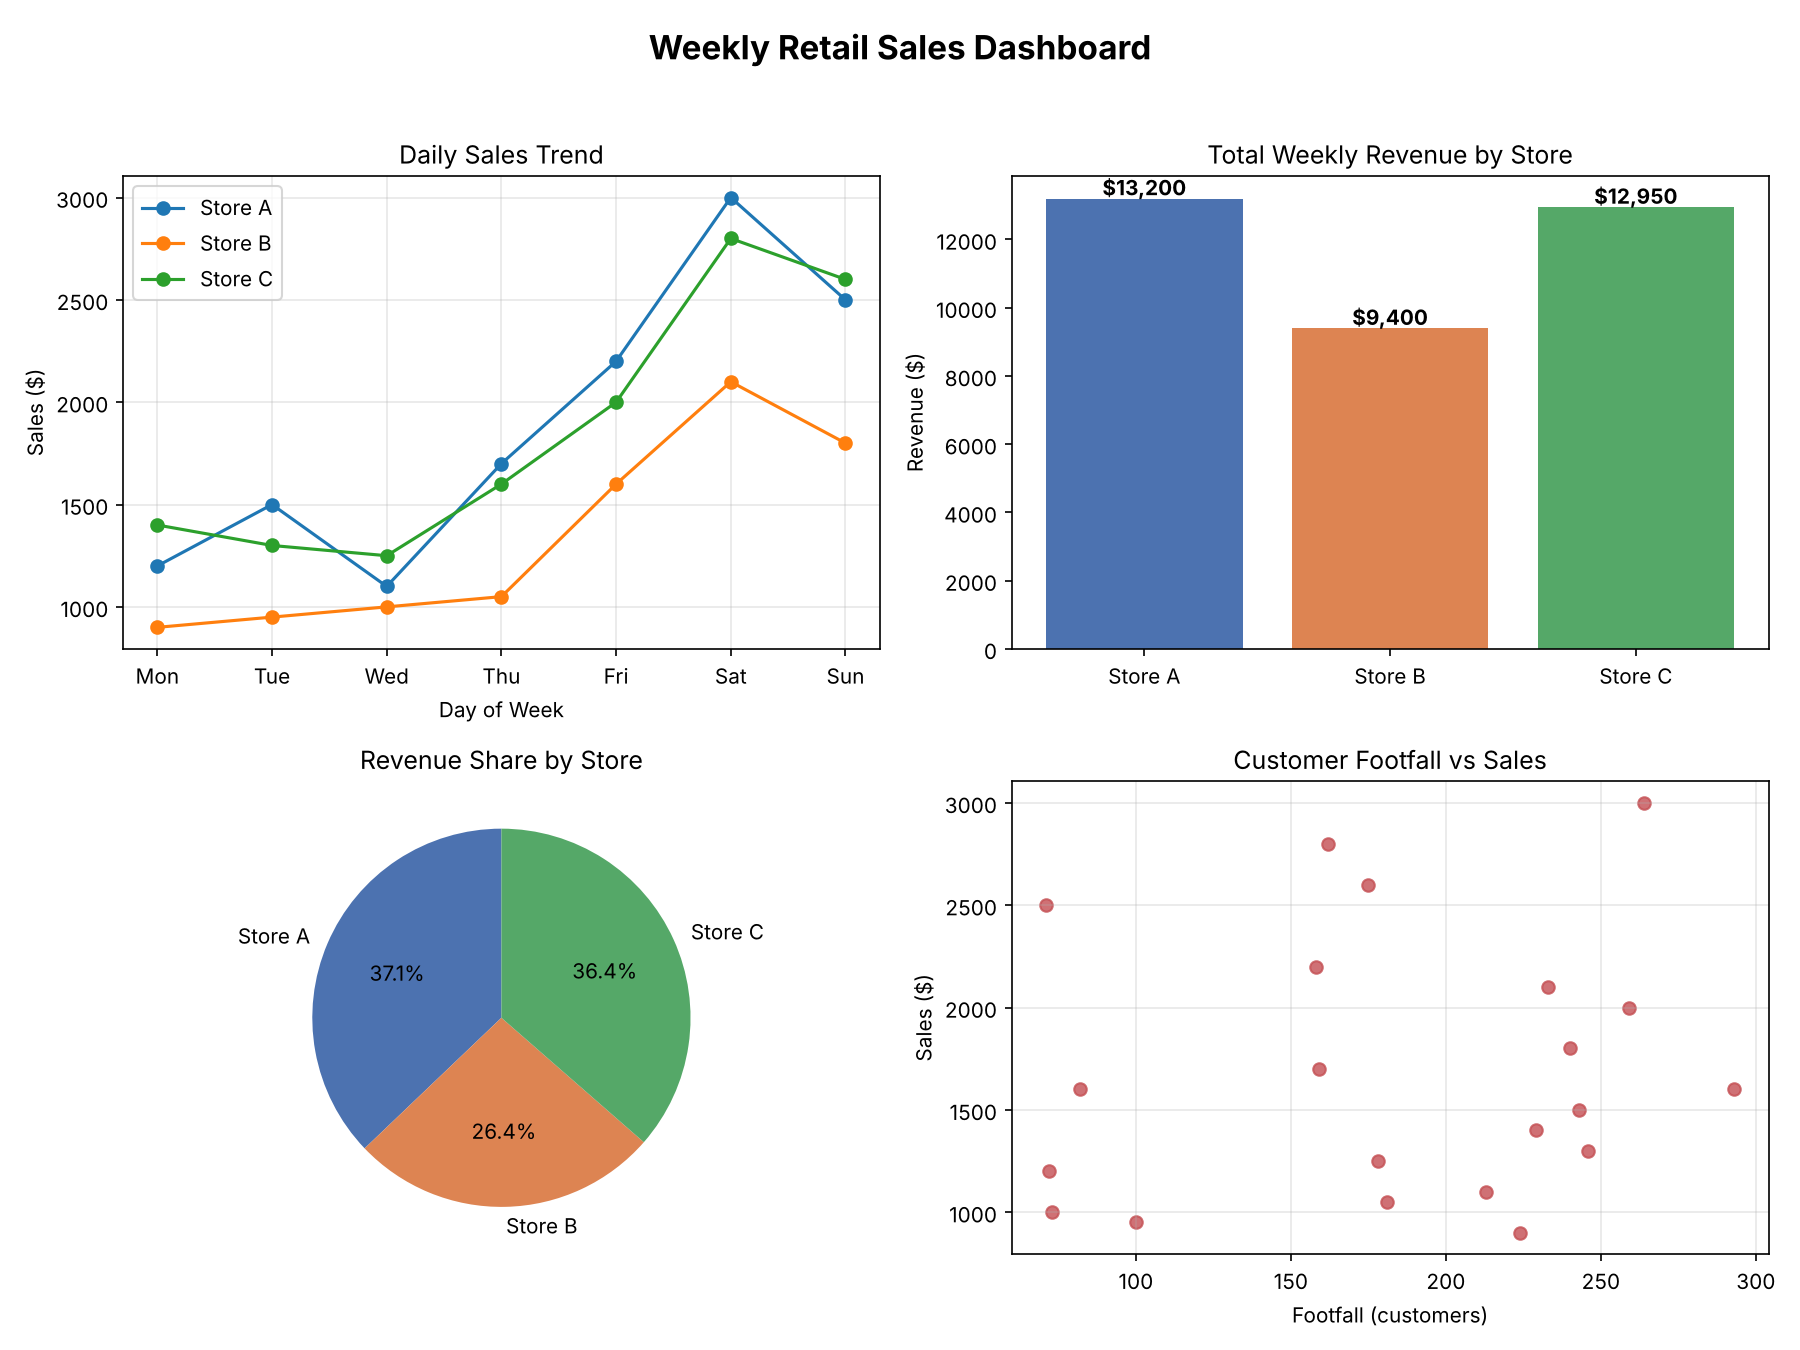

In [29]:
from IPython.display import Image, display
display(Image("sales_dashboard.png"))

### Show `tips_dashboard.png`

The script saves its chart to a file. This cell displays it.

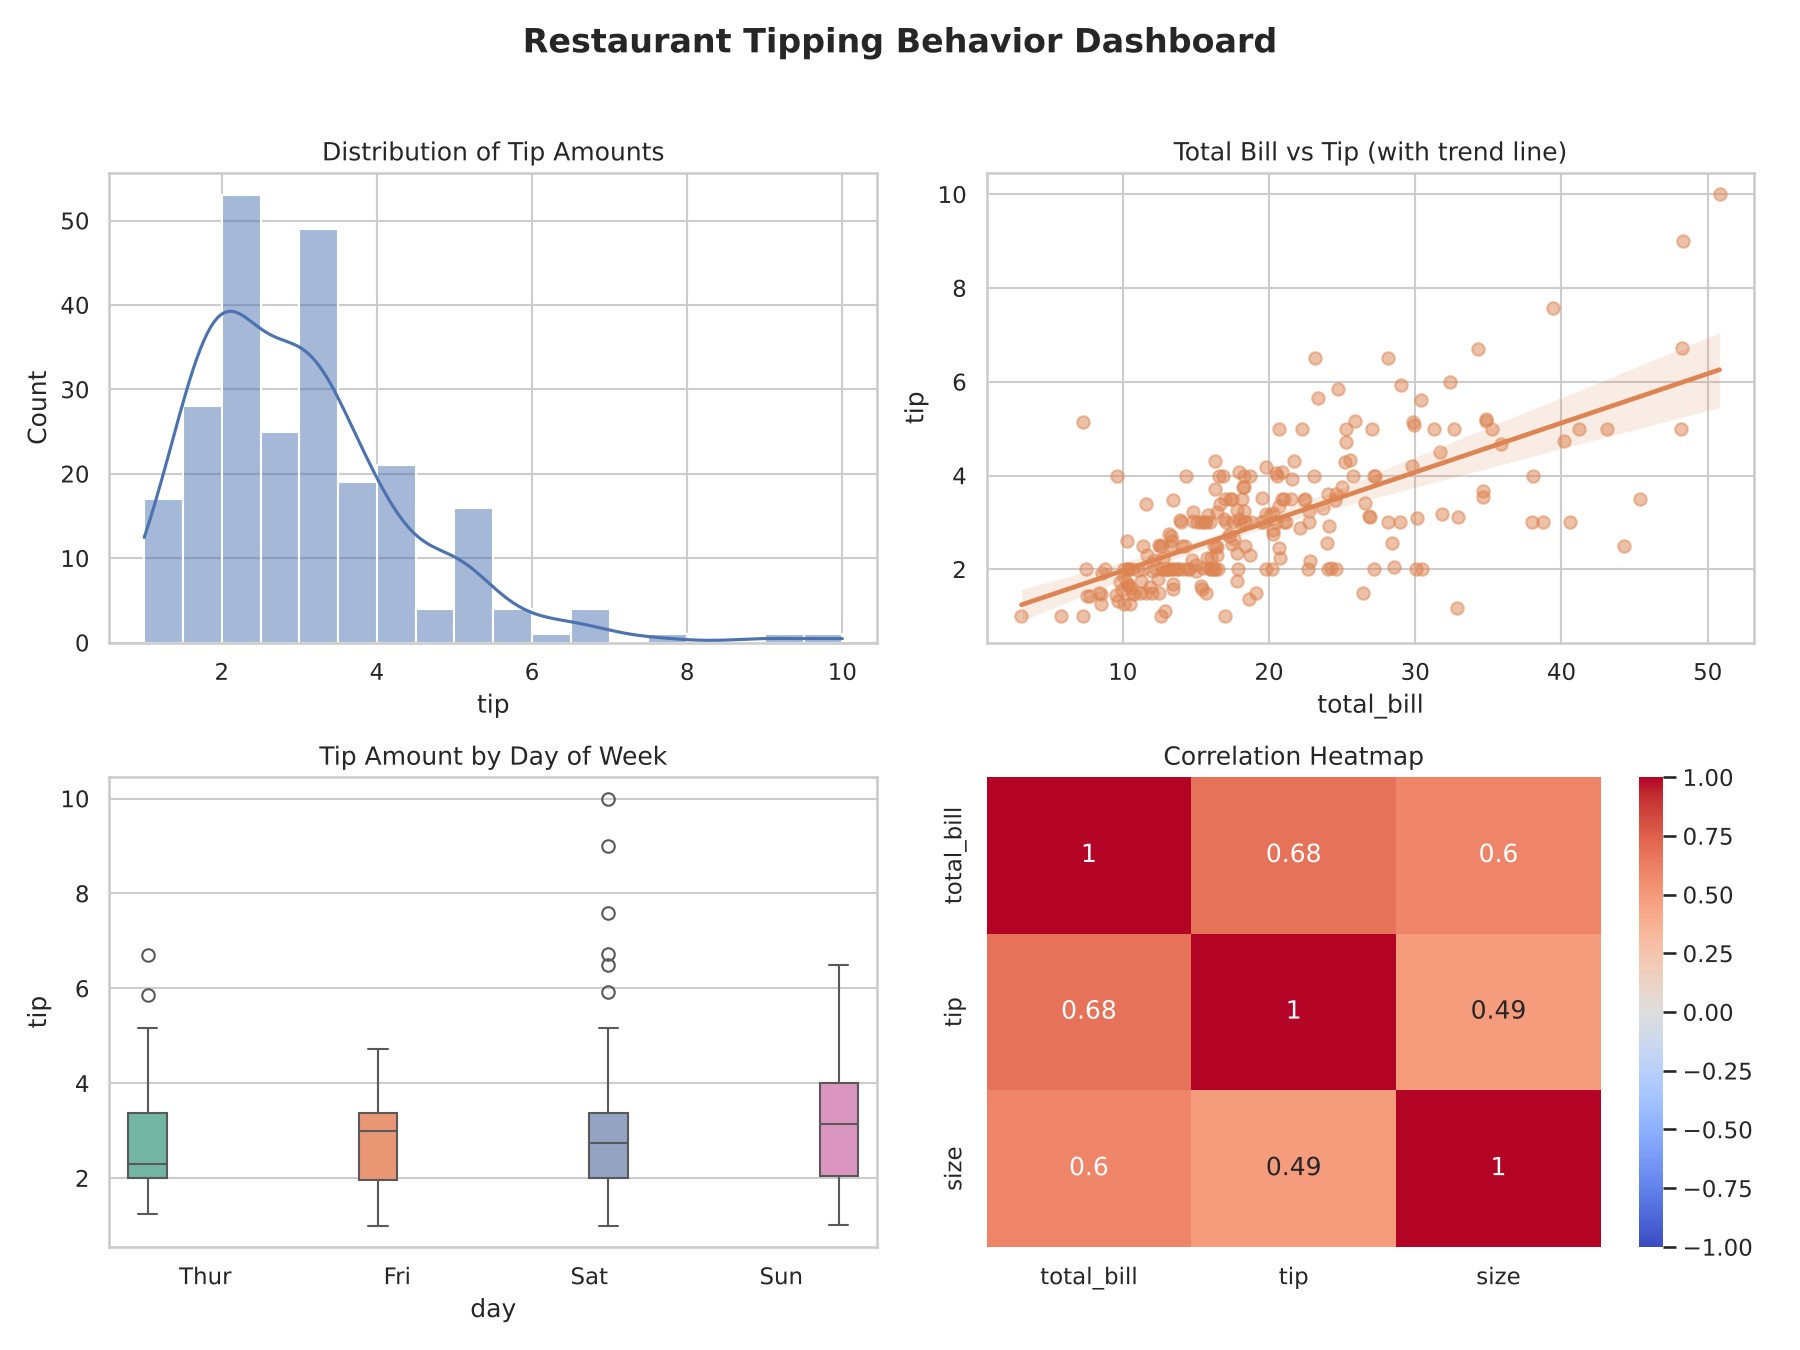

In [30]:
from IPython.display import Image, display
display(Image("tips_dashboard.png"))

---

💼 [LinkedIn](https://www.linkedin.com/in/prajwalskandas) · 💻 [GitHub](https://github.com/prajwalskandas31-sudo) · 🏠 [Course home](https://chipped-willow-4a2.notion.site/AI-Engineering-Course-Tech-with-Prajwal-4056f1ed006e819e88c5c3d15d1b2e0c)